# Datset description
## People aged between 15 and 28 that neither study nor work

**Source**: [DANE](https://www.dane.gov.co/index.php/estadisticas-por-tema/mercado-laboral/mercado-laboral-de-la-juventud)

# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [2]:
path = "./data/Jovenes_NOE_Tnal.csv"

df = pd.read_csv(
    path, encoding="utf-8", header=0,
    names=["fecha", "a", "b", "c", "d", "e", "total", "hombres", "mujeres"],
    usecols=["fecha", "hombres", "mujeres"]
)

## Clean data

In [3]:
df["fecha"] = df["fecha"].str.extract(r"([0-9]{2})", expand=False)
df["fecha"] = "20" + df["fecha"]

final = df.groupby("fecha").mean()

## Plot

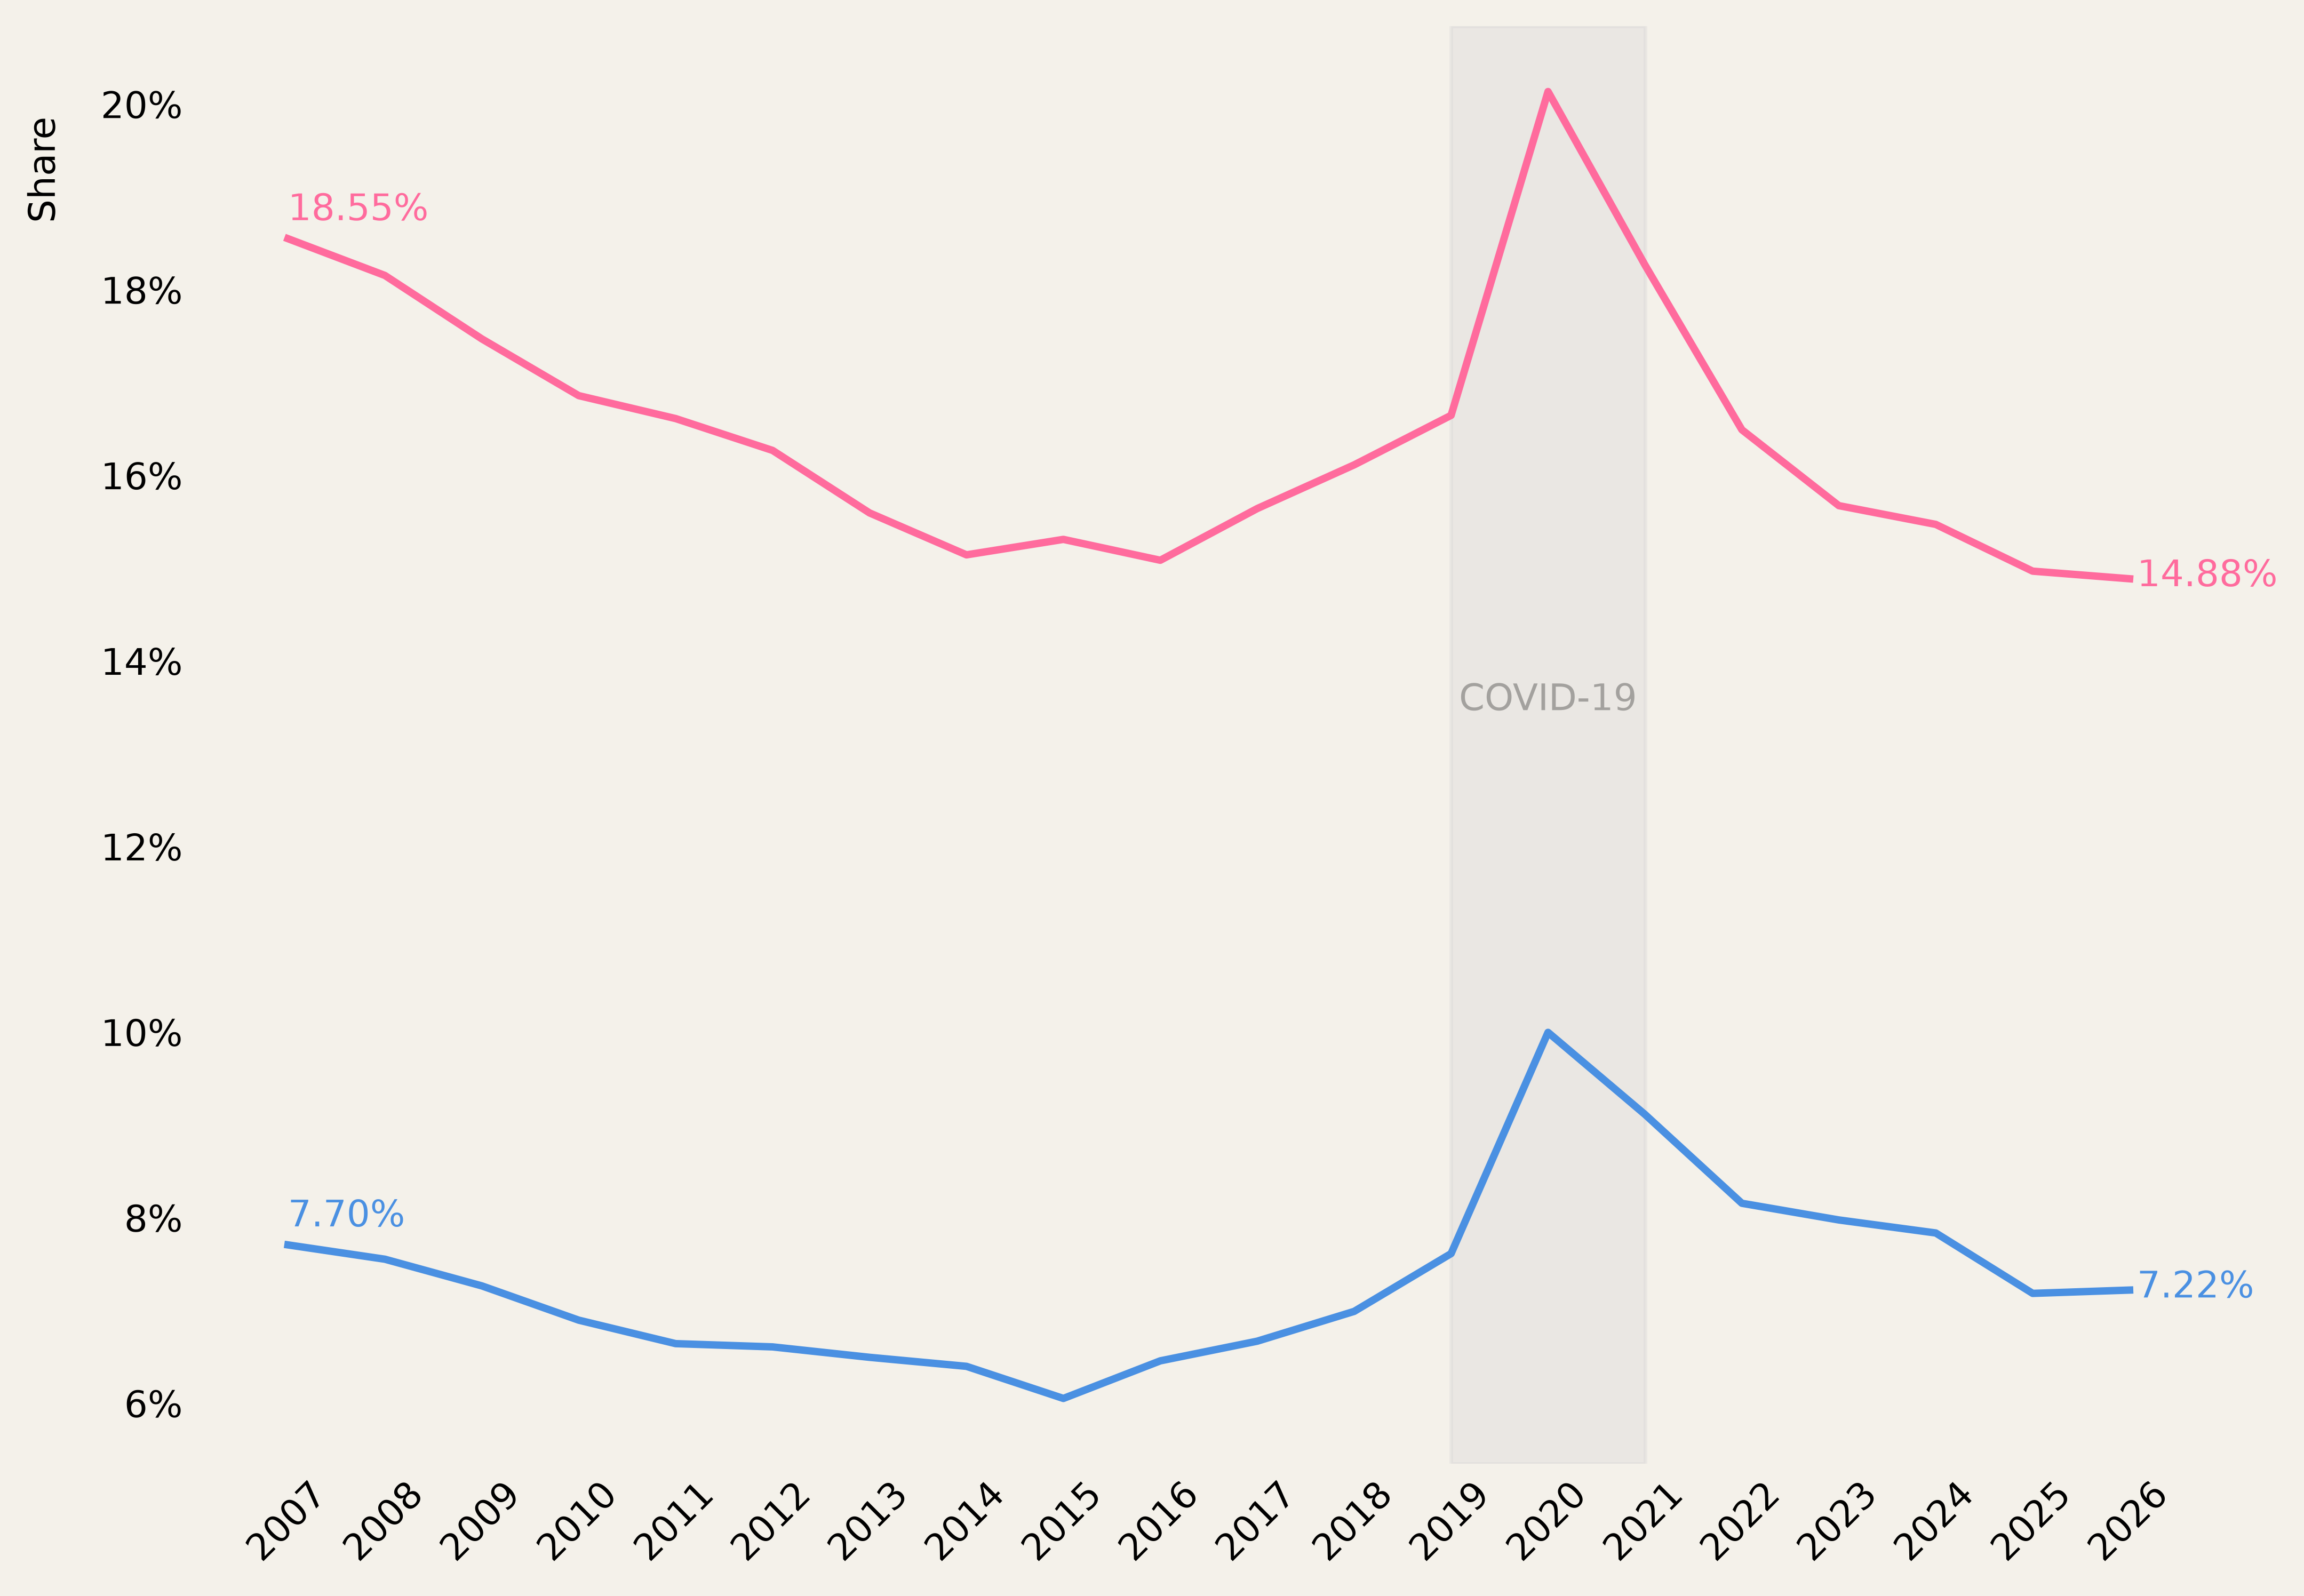

In [5]:
background = "#F4F1EA"
women_color = "#FF6B9D"
men_color = "#4a90e2"

x_axis = final.index

col_color = {
    "hombres": men_color,
    "mujeres": women_color
}

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

for gender in final.columns:
    plt.plot(
        x_axis, final[gender], color=col_color.get(gender),
        linewidth=2
    )

    initial_value = final.loc["2007", gender]
    final_value = final.loc["2026", gender]

    plt.annotate(
        f"{initial_value:.2f}%",
        xy=("2007", initial_value),
        xytext=(0,5),
        textcoords="offset points",
        color=col_color.get(gender)
    )

    plt.annotate(
        f"{final_value:.2f}%",
        xy=("2026", final_value),
        xytext=(2,-2),
        textcoords="offset points",
        color=col_color.get(gender)
    )

plt.xticks(x_axis, rotation=45)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Share", labelpad=10, fontsize=10, y=0.9)

plt.axvspan("2019", "2021", color="#D3D3D3", alpha=0.3)

middle = (final.loc["2020", "mujeres"] + final.loc["2020", "hombres"]) / 2

plt.annotate(
    "COVID-19",
    xy=("2020", middle),
    xytext=(0, -40),
    textcoords="offset points",
    color="black",
    ha="center",
    alpha=0.3
)

plt.show()